<a href="https://colab.research.google.com/github/Akash99950/4SF25CI015_3B/blob/main/MILESTONE_1_SALES_ANALYSIS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
df= pd.read_csv("superstore.csv")

print(df.head())

   Row ID        Order ID  Order Date   Ship Date     Ship Mode Customer ID  \
0       1  US-2017-100000  03/02/2017  08/02/2017   First Class    CU-78501   
1       2  US-2017-100001  11/05/2017  15/05/2017      Same Day    CU-50540   
2       3  US-2014-100002  04/04/2014  11/04/2014  Second Class    CU-90380   
3       4  US-2015-100003  16/06/2015  20/06/2015   First Class    CU-46976   
4       5  US-2015-100004  17/11/2015  23/11/2015      Same Day    CU-49343   

  Customer Name      Segment        Country           City  ... Postal Code  \
0  Customer 179  Home Office  United States  New York City  ...       10001   
1   Customer 57     Consumer  United States    Los Angeles  ...       90001   
2  Customer 169  Home Office  United States        Atlanta  ...       30301   
3   Customer 82  Home Office  United States    Los Angeles  ...       90001   
4   Customer 41  Home Office  United States  New York City  ...       10001   

   Region Product ID         Category Sub-Category

In [12]:
print(df.head())

print(df.shape)

print(df.info())

print(df.describe())

print(df.columns)

print(df.isnull().sum())

   Row ID        Order ID  Order Date   Ship Date     Ship Mode Customer ID  \
0       1  US-2017-100000  03/02/2017  08/02/2017   First Class    CU-78501   
1       2  US-2017-100001  11/05/2017  15/05/2017      Same Day    CU-50540   
2       3  US-2014-100002  04/04/2014  11/04/2014  Second Class    CU-90380   
3       4  US-2015-100003  16/06/2015  20/06/2015   First Class    CU-46976   
4       5  US-2015-100004  17/11/2015  23/11/2015      Same Day    CU-49343   

  Customer Name      Segment        Country           City  ... Postal Code  \
0  Customer 179  Home Office  United States  New York City  ...       10001   
1   Customer 57     Consumer  United States    Los Angeles  ...       90001   
2  Customer 169  Home Office  United States        Atlanta  ...       30301   
3   Customer 82  Home Office  United States    Los Angeles  ...       90001   
4   Customer 41  Home Office  United States  New York City  ...       10001   

   Region Product ID         Category Sub-Category

DATA TRANSFORMATION

In [14]:
df.columns = df.columns.str.strip()

df = df.drop_duplicates()

df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)

df['Ship Date'] = pd.to_datetime(df['Ship Date'], dayfirst=True)

df['Year'] = df['Order Date'].dt.year

df['Month'] = df['Order Date'].dt.month

df['Shipping Days'] = (df['Ship Date'] - df['Order Date']).dt.days

df['Profit Margin'] = (df['Profit'] / df['Sales'].replace(0, np.nan)) * 100

print(df.head())

   Row ID        Order ID Order Date  Ship Date     Ship Mode Customer ID  \
0       1  US-2017-100000 2017-02-03 2017-02-08   First Class    CU-78501   
1       2  US-2017-100001 2017-05-11 2017-05-15      Same Day    CU-50540   
2       3  US-2014-100002 2014-04-04 2014-04-11  Second Class    CU-90380   
3       4  US-2015-100003 2015-06-16 2015-06-20   First Class    CU-46976   
4       5  US-2015-100004 2015-11-17 2015-11-23      Same Day    CU-49343   

  Customer Name      Segment        Country           City  ... Sub-Category  \
0  Customer 179  Home Office  United States  New York City  ...      Storage   
1   Customer 57     Consumer  United States    Los Angeles  ...        Paper   
2  Customer 169  Home Office  United States        Atlanta  ...  Accessories   
3   Customer 82  Home Office  United States    Los Angeles  ...      Binders   
4   Customer 41  Home Office  United States  New York City  ...       Chairs   

          Product Name    Sales Quantity Discount Profit

IDENTIFY NULL VALUES

In [15]:
print(df.isnull().sum())

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             5
Quantity          5
Discount          5
Profit            5
Year              0
Month             0
Shipping Days     0
Profit Margin    10
dtype: int64


HANDLE NULL VALUES USING MEAN IMPUTATION

In [16]:
cols = ['Sales', 'Quantity', 'Discount', 'Profit']

for col in cols:
    df[col] = df[col].fillna(df[col].mean())

print(df.isnull().sum())

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
Year              0
Month             0
Shipping Days     0
Profit Margin    10
dtype: int64


In [ ]:
#TOTAL SALES

In [13]:
import numpy as np
import pandas as  pd
print("Total Sales:", df['Sales'].sum())

Total Sales: 1137368.4899999998


TOTAL PROFIT

In [14]:
print("Total Profit:", df['Profit'].sum())

Total Profit: 57797.34


AVERAGE SALES

In [15]:
print("Average Sales:", df['Sales'].mean())

Average Sales: 1143.0839095477384


REGION WISE SALES

In [17]:
print(df.groupby('Region')['Sales'].sum())

Region
Central    290799.95
East       273280.10
South      288648.28
West       284640.16
Name: Sales, dtype: float64


YEAR WISE SALES

In [27]:
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)
df['Year'] = df['Order Date'].dt.year

print(df.groupby('Year')['Sales'].sum())

Year
2014    287282.64
2015    288572.82
2016    291405.80
2017    270107.23
Name: Sales, dtype: float64



TOP FIVE PRoducts
```
# This is formatted as code
```



In [29]:
print(df.groupby('Product Name')['Sales'].sum().sort_values(ascending=False).head(5))

Product Name
Conference Table    57399.95
Modern Bookcase     56092.78
Marker Set          54591.65
Desk Lamp           50806.13
Wireless Phone      49021.83
Name: Sales, dtype: float64


In [20]:
print(df.groupby('Product Name')['Sales'].sum().sort_values(ascending=False).head(5))

Product Name
Conference Table    57399.95
Modern Bookcase     56092.78
Marker Set          54591.65
Desk Lamp           50806.13
Wireless Phone      49021.83
Name: Sales, dtype: float64


REGION WISE PROFITS graph

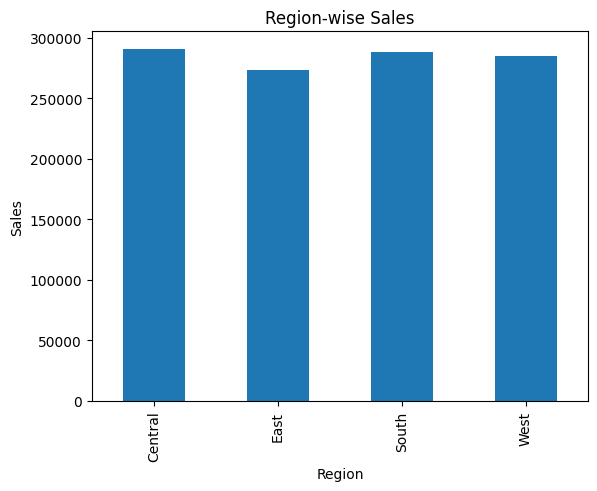

In [21]:
df.groupby('Region')['Sales'].sum().plot(kind='bar')

plt.title("Region-wise Sales")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.show()

category wise sales graph 2

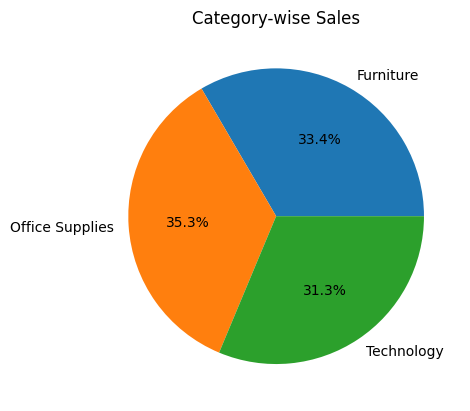

In [22]:
df.groupby('Category')['Sales'].sum().plot(kind='pie', autopct='%1.1f%%')

plt.title("Category-wise Sales")
plt.ylabel("")
plt.show()

profit distribution graph

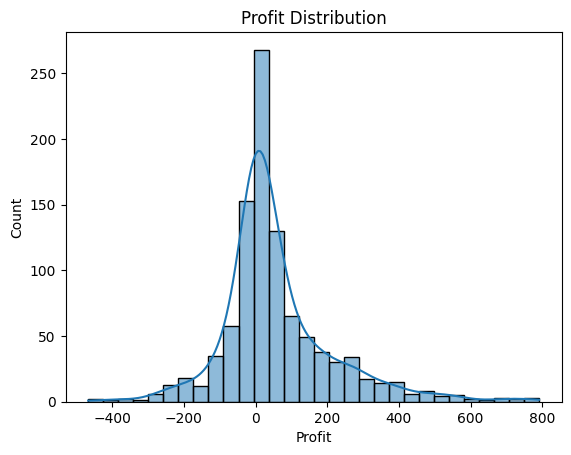

In [23]:
sns.histplot(df['Profit'], bins=30, kde=True)

plt.title("Profit Distribution")
plt.xlabel("Profit")
plt.show()

SAVE  CLEANED DATASET

In [25]:
df.to_csv('Cleaned_Superstore.csv', index=False)

print("Dataset saved successfully")

Dataset saved successfully


.HERE TOTAL SALES WERE CALCULATED
.REGIONAL SALES WERE COMPA.
.YEAR WISE TRENDS I ANALYSED
.I ALSO SED DIFFERENT CHARTS TO VISUALIZE THE RESULTS